In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
import time

В обучающей выборке 60000 примеров
В тестовой выборке 10000 примеров
Форма одного изображения (28, 28): 784
Форма массива меток train: (60000,)
Форма массива меток test: (10000,)


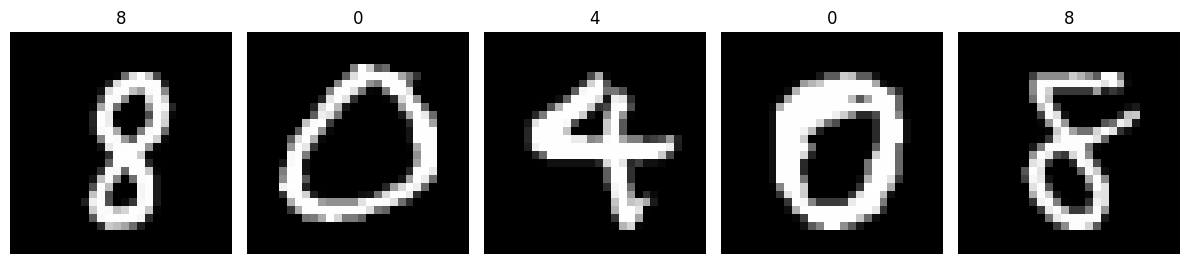

In [2]:
X, y = fetch_openml('mnist_784', version=1, as_frame=False, return_X_y=True)
y = y.astype(np.uint8)
X = X.astype(np.float32)

X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

X_train = X_train / 255.0
X_test = X_test / 255.0

print(f"В обучающей выборке {X_train.shape[0]} примеров")
print(f"В тестовой выборке {X_test.shape[0]} примеров")
print(f"Форма одного изображения (28, 28): {X_test.shape[1]}")
print(f"Форма массива меток train: {y_train.shape}")
print(f"Форма массива меток test: {y_test.shape}")

def visualization(X, y, num):
    plt.figure(figsize=(12, 4))
    rand = np.random.choice(len(X), num, replace=False)

    for i, idx in enumerate(rand):
        plt.subplot(1, num, i + 1)
        image = X[idx].reshape(28, 28)
        plt.imshow(image, cmap='gray')
        plt.title(f"{y[idx]}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

visualization(X_train, y_train, 5)

In [3]:
input_size = 784
output_size = 10
batch_size = 64
learning_rate = 0.1
hidden_size = 300
number_epochs = 20

In [4]:
def initialize_weights(input_size, hidden_size, output_size):
    np.random.seed(42)
    W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
    b2 = np.zeros((1, output_size))
    return W1, b1, W2, b2

W1, b1, W2, b2 = initialize_weights(input_size, hidden_size, output_size)

In [5]:
def ReLU(v):
    return np.maximum(0, v)

def softmax(u):
    exp_u = np.exp(u - np.max(u, axis=1, keepdims=True))
    return exp_u / np.sum(exp_u, axis=1, keepdims=True)

def forward_pass(X, W1, b1, W2, b2):
    f = np.matmul(X, W1) + b1
    v = ReLU(f)
    g = np.matmul(v, W2) + b2
    u = softmax(g)

    values = (X, f, v, u)
    return u, values

def backward_pass(values, y_true, W2):
    X, f, v, u = values
    batch_size = X.shape[0]

    delta2 = u.copy()
    delta2[np.arange(batch_size), y_true] -= 1.0
    delta2 /= batch_size
    delta1 = np.matmul(delta2, W2.T) * (f > 0).astype(float)

    dW2 = np.matmul(v.T, delta2)
    db2 = np.sum(delta2, axis=0, keepdims=True)
    dW1 = np.matmul(X.T, delta1)
    db1 = np.sum(delta1, axis=0, keepdims=True)

    return (dW1, db1, dW2, db2)

def update_weights(W1, b1, W2, b2, gradients, learning_rate):
    dW1, db1, dW2, db2 = gradients
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    return W1, b1, W2, b2

def compute_accuracy(X, y_true, W1, b1, W2, b2):
    u, _ = forward_pass(X, W1, b1, W2, b2)
    predictions = np.argmax(u, axis=1)
    accuracy = np.mean(predictions == y_true)
    return accuracy

In [6]:
test_accuracies = []

for epoch in range(number_epochs):
    epoch_start_time = time.time()

    permutation = np.random.permutation(X_train.shape[0])
    X_train_permutation = X_train[permutation]
    y_train_permutation = y_train[permutation]

    for i in range(0, X_train.shape[0], batch_size):
        X_batch = X_train_permutation[i:i+batch_size]
        y_batch = y_train_permutation[i:i+batch_size]

        u, values = forward_pass(X_batch, W1, b1, W2, b2)
        gradients = backward_pass(values, y_batch, W2)
        W1, b1, W2, b2 = update_weights(W1, b1, W2, b2, gradients, learning_rate)

    train_accuracy = compute_accuracy(X_train, y_train, W1, b1, W2, b2)
    test_accuracy = compute_accuracy(X_test, y_test, W1, b1, W2, b2)
    test_accuracies.append(test_accuracy)

    train_error = 1 - train_accuracy
    epoch_time = time.time() - epoch_start_time

    print(f"Эпоха {epoch+1}/{number_epochs}:")
    print(f"Ошибка классификации на тренировочном наборе данных: {train_error:.4f} ({train_error*100:.2f}%)")
    print(f"Время выполнения эпохи: {epoch_time:.2f} с")
    print()

test_error = 1 - test_accuracies[-1]
print(f"Ошибка классификации на тестовом наборе данных: {test_error*100:.2f}%")

Эпоха 1/20:
Ошибка классификации на тренировочном наборе данных: 0.0641 (6.41%)
Время выполнения эпохи: 7.57 с

Эпоха 2/20:
Ошибка классификации на тренировочном наборе данных: 0.0428 (4.28%)
Время выполнения эпохи: 7.41 с

Эпоха 3/20:
Ошибка классификации на тренировочном наборе данных: 0.0321 (3.21%)
Время выполнения эпохи: 7.84 с

Эпоха 4/20:
Ошибка классификации на тренировочном наборе данных: 0.0257 (2.57%)
Время выполнения эпохи: 7.01 с

Эпоха 5/20:
Ошибка классификации на тренировочном наборе данных: 0.0242 (2.42%)
Время выполнения эпохи: 8.84 с

Эпоха 6/20:
Ошибка классификации на тренировочном наборе данных: 0.0183 (1.83%)
Время выполнения эпохи: 6.45 с

Эпоха 7/20:
Ошибка классификации на тренировочном наборе данных: 0.0160 (1.60%)
Время выполнения эпохи: 9.56 с

Эпоха 8/20:
Ошибка классификации на тренировочном наборе данных: 0.0138 (1.38%)
Время выполнения эпохи: 6.36 с

Эпоха 9/20:
Ошибка классификации на тренировочном наборе данных: 0.0115 (1.15%)
Время выполнения эпохи: 

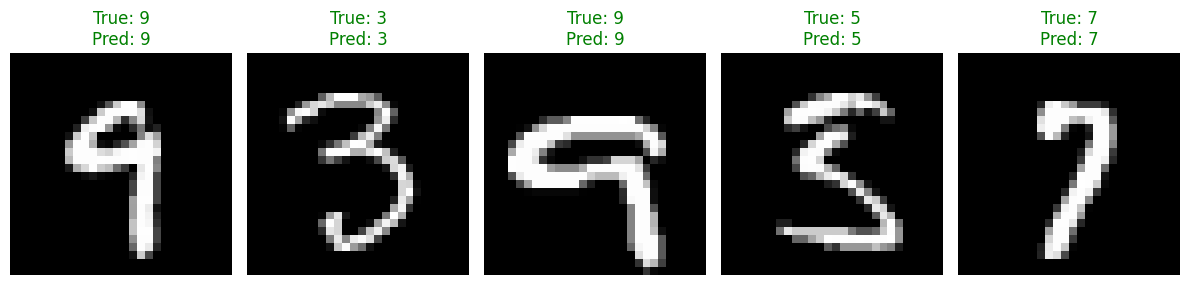

In [7]:
def visualize_predictions(X, y, W1, b1, W2, b2, num):
    u, _ = forward_pass(X, W1, b1, W2, b2)
    predictions = np.argmax(u, axis=1)

    plt.figure(figsize=(12, 4))
    rand = np.random.choice(len(X), num, replace=False)

    for i, idx in enumerate(rand):
        plt.subplot(1, num, i + 1)
        image = X[idx].reshape(28, 28)
        plt.imshow(image, cmap='gray')
        color = 'green' if predictions[idx] == y[idx] else 'red'
        plt.title(f"True: {y[idx]}\nPred: {predictions[idx]}", color=color)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

visualize_predictions(X_test, y_test, W1, b1, W2, b2, 5)